# 17 · Análisis exploratorio: combinaciones de Visa y Master

**Etapa 22 del plan.** El dataset trae cada tarjeta por separado: saldo de Visa, saldo de Master, límite de Visa, límite de Master. Nunca miramos al cliente con las dos tarjetas juntas, ni cuánto de su límite usa. La cátedra de 2021 armaba esas combinaciones en `951_dataset_epic.r`: sumas, mínimos y máximos entre las dos tarjetas, y cocientes contra el límite total.

**Pregunta:** sobre `ACH_4_P3`, la vigente del `15`, ¿cuánto dinero suman esas combinaciones?

| Configuración | Columnas | Qué agrega a `ACH_4` |
|---|---:|---|
| `ACH_4_P3` | 1.180 | Nada: es la referencia. Sus predicciones se leen del `15` |
| `ACH_4_MV_P3` | 1.223 | 43 combinaciones del mes |
| `ACH_4_MVH_P3` | 1.395 | Las 43, más sus lags y deltas de 1 y 2 meses, como el baseline hace con cada variable. **Esta decide** |

Mismo banco temporal del `15`: para evaluar un mes, el modelo entrena con todos los meses desde 201903 hasta dos meses antes. Se evalúan 201906 a 201910, con 5 semillas, 296 árboles y `BAJA+2` pesando el triple.

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada. No carga 201911 ni 201912. **No escribe en `exp/03/` a `exp/16/` ni en los `resultados/03_*` a `16_*`:** solo los lee.

Ficha: `fichas/etapa_22_visa_master.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Los modelos ya hechos no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_15 = Path('../exp/15')                          # solo se lee
EXP = Path('../exp/17')
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201910                                   # nada posterior entra a este notebook
MESES_TABLA = [201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910]
MESES_EVALUADOS = [201906, 201907, 201908, 201909, 201910]
MESES_FINALES = [201909, 201910]
MESES_CONSIGNA = [201903, 201904, 201905, 201906]
ULTIMOS = 4
DISTANCIA = 2                                       # la clase de un mes se conoce dos meses después
MESES_TRAIN = MESES_CONSIGNA                        # los pide `construir`; acá cada modelo elige su ventana
MESES_EVAL = MESES_FINALES
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]   # como en el 06 y el 12

CONTROL = 'AC'
BASE_CURADA = 'ACH'
JUNTAS = 'ACH_4'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}
CANDIDATAS = ['ACH_V', 'ACH_Q', 'ACH_T', 'ACH_Z']
REFERENCIA = 'ACH_4_P3'                             # la vigente del 15: sus predicciones se leen de exp/15
PESO_B2 = 3
CONFIGS = {'ACH_4_MV_P3': 'MV', 'ACH_4_MVH_P3': 'MVH'}   # configuración: bloque que se agrega a ACH_4
DECIDE = 'ACH_4_MVH_P3'
CONTRASTES = [('ACH_4_MVH_P3', REFERENCIA), ('ACH_4_MV_P3', REFERENCIA), ('ACH_4_MVH_P3', 'ACH_4_MV_P3')]
HIPOTESIS = {
    'ACH_4_MVH_P3': 'Las combinaciones de Visa y Master, con sus lags y deltas, ganan más que ACH_4_P3',
    'ACH_4_MV_P3': 'Solo las combinaciones del mes',
}
LAGS_MV = [1, 2]                                    # como el baseline: lag y delta de 1 y 2 meses
ROTO_NUEVO = ('Visa_mfinanciacion_limite', 201904)  # media x6 y sin ceros: la regla del 01 no lo detectó
UMBRAL = 1.0                                        # M por mes, fijado en la ficha
FOTOS = 9                                           # 201910 llega hasta 201901

N_CURADAS = 30
MINIMO_PREVIOS = 2
BLOQUE = 20_000                                     # filas por bloque al armar las tablas

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_TABLA = (1_037_551, 5_042)                 # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880, 'ACH_4': 1_180, 'MV': 43, 'MVH': 215}
N_MES = 152
ESPERADO_ROTOS = 23


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 8: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[0123456]_*')]
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 44


## 2. Dataset y funciones de evaluación

**Control 1:** filas y `BAJA+2` de 201903 a 201910. **Control 2:** nada posterior a 201910 entra al notebook. La clase de 201911 y 201912 nunca se carga.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
del base
gc.collect()
print(f'Dataset cargado en {time.time() - t0:.0f} s')

Dataset cargado en 2 s


## 3. Tablas de `ACH_4`

Las mismas columnas de `ACH_4` del `15`: 1.180, el baseline más la historia curada y los cuatro bloques del `14`.

**Control 4:** una columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)


def cero_fijo(x, mes):
    """Percentil dentro del mes: positivos de 0 a 1, negativos de 0 a -1, y el cero en 0."""
    s = pd.Series(x)
    arriba = s.where(s > 0).groupby(mes).rank(pct=True).fillna(0)
    abajo = (-s).where(s < 0).groupby(mes).rank(pct=True).fillna(0)
    return (arriba - abajo).where(s.notna()).to_numpy()


def bloques_nuevos(filas, X, indice, clave, foto_mes):
    """Cada fila usa solo fotos de su mes o anteriores. El percentil usa solo su mes."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(FOTOS + 1)]
    mes = foto_mes[filas]
    salida = {b: {} for b in CANDIDATAS}
    with np.errstate(invalid='ignore', divide='ignore'):
        for v in CURADAS:
            j = VARIABLES.index(v)
            H = np.stack([np.where(p >= 0, X[p, j], np.nan) for p in pos]).astype(np.float64)
            a, b, c, d = H[:4]
            dif = np.stack([a - b, b - c, c - d])
            valido = ~np.isnan(dif)
            cuantos = valido.sum(axis=0)
            alcanza = cuantos >= MINIMO_PREVIOS
            media = np.where(valido, dif, 0.0).sum(axis=0) / cuantos
            desvio = np.sqrt(np.where(valido, (dif - media) ** 2, 0.0).sum(axis=0) / cuantos)
            salida['ACH_V'][f'{v}_std3'] = np.stack([a, b, c]).std(axis=0)
            salida['ACH_V'][f'{v}_dstd3'] = np.where(alcanza, desvio, np.nan)
            salida['ACH_Q'][f'{v}_q4'] = (a + b) / 2 - (c + d) / 2
            salida['ACH_Q'][f'{v}_peor3'] = np.where(alcanza, np.where(valido, dif, np.inf).min(axis=0), np.nan)
            salida['ACH_Q'][f'{v}_caidas3'] = np.where(alcanza, (dif < 0).sum(axis=0), np.nan)
            P = H[1:]
            valido = ~np.isnan(P)
            cuantos = valido.sum(axis=0)
            alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
            maximo = np.where(valido, P, -np.inf).max(axis=0)
            media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
            salida['ACH_T'][f'{v}_relmaxT'] = np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan)
            salida['ACH_T'][f'{v}_relmediaT'] = np.where(alcanza & (np.abs(media) > EPSILON), a / media, np.nan)
            salida['ACH_T'][f'{v}_desdemaxT'] = np.where(alcanza, np.where(np.isnan(H), -np.inf, H).argmax(axis=0), np.nan)
            salida['ACH_Z'][f'{v}_zc1'] = cero_fijo(a - b, mes)
            salida['ACH_Z'][f'{v}_zc2'] = cero_fijo(a - c, mes)
    return {b: (np.column_stack(list(c.values())).astype(np.float32), list(c)) for b, c in salida.items()}


t0 = time.time()
T = construir(BASE_CURADA, meses=MESES_TABLA)
assert T['F'].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[BASE_CURADA]), T['F'].shape
assert T['columnas'][:N_MES] == VARIABLES and T['columnas'][ESPERADO_N_VARIABLES[CONTROL]].endswith('_ratio3')
assert (CLASE[T['filas']] == 'BAJA+2').sum() == ESPERADO_TABLA[1]         # control 1
B = bloques_nuevos(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape[1] for b, v in B.items()} == {'ACH_V': 60, 'ACH_Q': 90, 'ACH_T': 90, 'ACH_Z': 60}

CLIENTE_FILA = CLAVE[T['filas']] // 100_000
CLIENTES, POS_CLIENTE = np.unique(CLIENTE_FILA, return_inverse=True)

# Control 4: sin fuga. Con los datos cortados en el mes, cada columna tiene que dar lo mismo.
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloques_nuevos(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in CANDIDATAS:
        assert np.array_equal(C[b][0], B[b][0][en_mes], equal_nan=True), (b, corte)
    del C

# Control 6: fórmulas a mano
rng = np.random.default_rng(SEMILLA_PRIMIGENIA)
muestra = rng.choice(len(T['filas']), size=300, replace=False)
col = {b: {c: i for i, c in enumerate(B[b][1])} for b in CANDIDATAS}


def igual(bloque, nombre_columna, fila, esperado):
    valor = B[bloque][0][fila, col[bloque][nombre_columna]]
    if esperado is None:
        assert np.isnan(valor), (nombre_columna, fila, valor)
    else:
        np.testing.assert_allclose(valor, esperado, rtol=1e-3, atol=1e-3, err_msg=nombre_columna)


for v in CURADAS[:3]:
    serie = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
    for i in muestra:
        clave = CLAVE[T['filas'][i]]
        y = [serie.get(clave - k, np.nan) for k in range(FOTOS + 1)]
        igual('ACH_V', f'{v}_std3', i, None if np.isnan(y[:3]).any() else float(np.std(y[:3])))
        igual('ACH_Q', f'{v}_q4', i, None if np.isnan(y[:4]).any() else (y[0] + y[1]) / 2 - (y[2] + y[3]) / 2)
        dif = [y[k] - y[k + 1] for k in range(3)]
        hay = [x for x in dif if not np.isnan(x)]
        igual('ACH_V', f'{v}_dstd3', i, float(np.std(hay)) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_peor3', i, min(hay) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_caidas3', i, sum(x < 0 for x in hay) if len(hay) >= 2 else None)
        previos = [x for x in y[1:] if not np.isnan(x)]
        alcanza = len(previos) >= 2 and not np.isnan(y[0])
        igual('ACH_T', f'{v}_relmaxT', i, y[0] / max(previos) if alcanza and max(previos) > EPSILON else None)
        igual('ACH_T', f'{v}_relmediaT', i, y[0] / np.mean(previos) if alcanza and abs(np.mean(previos)) > EPSILON else None)
        igual('ACH_T', f'{v}_desdemaxT', i, int(np.nanargmax(y)) if alcanza else None)
v = CURADAS[0]
en_mes = T['mes_fila'] == 201906
d = T['F'][en_mes, T['columnas'].index(f'{v}_delta1')].astype(np.float64)
z = B['ACH_Z'][0][en_mes, col['ACH_Z'][f'{v}_zc1']]
assert (np.isnan(d) == np.isnan(z)).all() and (np.sign(d[~np.isnan(d)]) == np.sign(z[~np.isnan(z)])).all()
hay = d > 0
np.testing.assert_allclose(z[hay], stats.rankdata(d[hay]) / hay.sum(), rtol=1e-5)
print(f'Tablas y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Tablas y controles 4 y 6 OK en 29 s · memoria máxima 4.0 GB


## 4. Combinaciones de Visa y Master

Las mismas de `951_dataset_epic.r`, la receta de la cátedra 2021:

| Grupo | Columnas | Cómo se calcula |
|---|---:|---|
| Estado de las dos tarjetas (`mv_status01` a `07`) | 7 | Máximo, suma y codificaciones de `Visa_status` y `Master_status`. Una tarjeta que falta vale 10 |
| Sumas (`mv_msaldototal`, `mv_mlimitecompra`, `mv_mpagado`, …) | 16 | Visa + Master. Si un cliente no tiene ninguna, da 0, como en la cátedra |
| Fechas (`mv_Fvencimiento`, `mv_Finiciomora`, `mv_fultimo_cierre`, `mv_fechaalta`) | 4 | El mínimo de las dos en vencimiento e inicio de mora; el máximo en último cierre y alta |
| Cocientes (`mvr_*`) | 16 | Contra el límite de compra total: saldo, consumos, pagos, adelantos, pago mínimo. Además, la parte de cada tarjeta en el límite, y la parte en pesos y en dólares del saldo |

**Meses rotos:** si una de las dos tarjetas tiene roto ese mes, la combinación queda vacía (NA). Así no se suma una tarjeta sola como si fuera el total. Además de la lista del `01`, se trata como roto `Visa_mfinanciacion_limite` de 201904. Las columnas originales de `ACH_4` no cambian, para que la referencia siga siendo la del `15`.

**Historia (`MVH`):** a las 43 se les agrega el lag y el delta de 1 y 2 meses, igual que el baseline hace con cada variable original.

**Control 4:** cada columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes, y los meses rotos vacíos.

In [4]:
SUMAS = ['mfinanciacion_limite', 'msaldototal', 'msaldopesos', 'msaldodolares', 'mconsumospesos', 'mconsumosdolares',
         'mlimitecompra', 'madelantopesos', 'madelantodolares', 'mpagado', 'mpagospesos', 'mpagosdolares',
         'mconsumototal', 'cconsumos', 'cadelantosefectivo', 'mpagominimo']
MINIMOS = ['Fvencimiento', 'Finiciomora']
MAXIMOS = ['fultimo_cierre', 'fechaalta']
COCIENTES = [('mvr_Master_mlimitecompra', 'Master_mlimitecompra', 'mv_mlimitecompra'),
             ('mvr_Visa_mlimitecompra', 'Visa_mlimitecompra', 'mv_mlimitecompra'),
             ('mvr_msaldototal', 'mv_msaldototal', 'mv_mlimitecompra'),
             ('mvr_msaldopesos', 'mv_msaldopesos', 'mv_mlimitecompra'),
             ('mvr_msaldopesos2', 'mv_msaldopesos', 'mv_msaldototal'),
             ('mvr_msaldodolares', 'mv_msaldodolares', 'mv_mlimitecompra'),
             ('mvr_msaldodolares2', 'mv_msaldodolares', 'mv_msaldototal'),
             ('mvr_mconsumospesos', 'mv_mconsumospesos', 'mv_mlimitecompra'),
             ('mvr_mconsumosdolares', 'mv_mconsumosdolares', 'mv_mlimitecompra'),
             ('mvr_madelantopesos', 'mv_madelantopesos', 'mv_mlimitecompra'),
             ('mvr_madelantodolares', 'mv_madelantodolares', 'mv_mlimitecompra'),
             ('mvr_mpagado', 'mv_mpagado', 'mv_mlimitecompra'),
             ('mvr_mpagospesos', 'mv_mpagospesos', 'mv_mlimitecompra'),
             ('mvr_mpagosdolares', 'mv_mpagosdolares', 'mv_mlimitecompra'),
             ('mvr_mconsumototal', 'mv_mconsumototal', 'mv_mlimitecompra'),
             ('mvr_mpagominimo', 'mv_mpagominimo', 'mv_mlimitecompra')]
ROTOS_MV = {(v, int(m)) for v, m in rotos.itertuples(index=False)} | {ROTO_NUEVO}
assert all(f'{t}_{c}' in VARIABLES for t in ('Master', 'Visa') for c in SUMAS + MINIMOS + MAXIMOS)


def combinaciones(X, foto_mes):
    """Las 43 combinaciones del mes, fila por fila. Solo usan la foto de esa fila."""
    col = lambda v: X[:, VARIABLES.index(v)].astype(np.float64)
    roto = lambda v: np.isin(foto_mes, [m for w, m in ROTOS_MV if w == v])
    s = {}
    ms, vs = col('Master_status'), col('Visa_status')
    m10, v10 = np.where(np.isnan(ms), 10, ms), np.where(np.isnan(vs), 10, vs)
    s['mv_status01'] = np.fmax(ms, vs)
    s['mv_status02'] = ms + vs
    s['mv_status03'] = np.maximum(m10, v10)
    s['mv_status04'] = m10 + v10
    s['mv_status05'] = m10 + 100 * v10
    s['mv_status06'] = np.where(np.isnan(vs), m10, vs)
    s['mv_status07'] = np.where(np.isnan(ms), v10, ms)
    for c in SUMAS:
        s[f'mv_{c}'] = np.nan_to_num(col(f'Master_{c}')) + np.nan_to_num(col(f'Visa_{c}'))
    for c in MINIMOS:
        s[f'mv_{c}'] = np.fmin(col(f'Master_{c}'), col(f'Visa_{c}'))
    for c in MAXIMOS:
        s[f'mv_{c}'] = np.fmax(col(f'Master_{c}'), col(f'Visa_{c}'))
    for c in SUMAS + MINIMOS + MAXIMOS:
        s[f'mv_{c}'][roto(f'Master_{c}') | roto(f'Visa_{c}')] = np.nan
    with np.errstate(invalid='ignore', divide='ignore'):
        for nombre_c, num, den in COCIENTES:
            n = s[num] if num in s else col(num)
            s[nombre_c] = np.where(np.abs(s[den]) > EPSILON, n / s[den], np.nan)
    return np.column_stack(list(s.values())).astype(np.float32), list(s)


def bloque_mv(filas, X, indice, clave, foto_mes):
    """MV: las 43 del mes. MVH: además, lag y delta de 1 y 2 meses. Cada fila usa solo fotos de su mes o anteriores."""
    C, nombres = combinaciones(X, foto_mes)
    H = {}
    for k in [0] + LAGS_MV:
        p = indice.get_indexer(clave[filas] - k)
        H[k] = np.where((p >= 0)[:, None], C[np.maximum(p, 0)], np.float32(np.nan))
    partes, columnas = [H[0]], list(nombres)
    for k in LAGS_MV:
        partes += [H[k], H[0] - H[k]]
        columnas += [f'{n}_lag{k}' for n in nombres] + [f'{n}_delta{k}' for n in nombres]
    MVH = np.hstack(partes).astype(np.float32)
    return {'MV': (MVH[:, :len(nombres)], list(nombres)), 'MVH': (MVH, columnas)}


t0 = time.time()
BMV = bloque_mv(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape for b, v in BMV.items()} == {b: (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[b]) for b in BMV}
assert not set(BMV['MVH'][1]) & set(T['columnas'] + [c for b in CANDIDATAS for c in B[b][1]])

# Control 4: sin fuga
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloque_mv(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])['MVH'][0]
    assert np.array_equal(C, BMV['MVH'][0][T['mes_fila'] == corte], equal_nan=True), corte
    del C

# Control 6: fórmulas a mano, con pandas, fila por fila
col_mv = {c: i for i, c in enumerate(BMV['MVH'][1])}
serie = {v: pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
         for v in ['Master_msaldototal', 'Visa_msaldototal', 'Master_mlimitecompra', 'Visa_mlimitecompra',
                   'Master_Finiciomora', 'Visa_Finiciomora', 'Master_status', 'Visa_status']}


def a_mano(clave):
    """Valores esperados para una clave cliente-período; NA si la foto no existe."""
    if clave not in INDICE:
        return None
    g = {v: serie[v][clave] for v in serie}
    suma = lambda c: (0 if np.isnan(g[f'Master_{c}']) else g[f'Master_{c}']) + (0 if np.isnan(g[f'Visa_{c}']) else g[f'Visa_{c}'])
    saldo, limite = suma('msaldototal'), suma('mlimitecompra')
    fechas = [x for x in (g['Master_Finiciomora'], g['Visa_Finiciomora']) if not np.isnan(x)]
    m10 = 10 if np.isnan(g['Master_status']) else g['Master_status']
    v10 = 10 if np.isnan(g['Visa_status']) else g['Visa_status']
    return {'mv_msaldototal': saldo, 'mv_mlimitecompra': limite,
            'mvr_msaldototal': saldo / limite if abs(limite) > EPSILON else np.nan,
            'mv_Finiciomora': min(fechas) if fechas else np.nan, 'mv_status05': m10 + 100 * v10}


rng = np.random.default_rng(SEMILLA_PRIMIGENIA + 17)
for i in rng.choice(len(T['filas']), size=300, replace=False):
    clave = CLAVE[T['filas'][i]]
    hoy = a_mano(clave)
    for c, x in hoy.items():
        np.testing.assert_allclose(BMV['MVH'][0][i, col_mv[c]], x, rtol=1e-4, atol=1e-3, err_msg=c)
    for k in LAGS_MV:
        antes = a_mano(clave - k)
        for c in ('mvr_msaldototal', 'mv_msaldototal'):
            lag = np.nan if antes is None else antes[c]
            np.testing.assert_allclose(BMV['MVH'][0][i, col_mv[f'{c}_lag{k}']], lag, rtol=1e-4, atol=1e-3, err_msg=f'{c}_lag{k}')
            np.testing.assert_allclose(BMV['MVH'][0][i, col_mv[f'{c}_delta{k}']], hoy[c] - lag, rtol=1e-4, atol=1e-1, err_msg=f'{c}_delta{k}')

# Meses rotos: la combinación queda vacía
vacia = lambda c, m: np.isnan(BMV['MVH'][0][T['mes_fila'] == m, col_mv[c]]).all()
assert vacia('mv_fultimo_cierre', 201907) and vacia('mv_mfinanciacion_limite', 201904)
assert vacia('mv_mfinanciacion_limite_lag1', 201905) and vacia('mv_mfinanciacion_limite_delta2', 201906)
assert not vacia('mv_mfinanciacion_limite', 201905) and not vacia('mv_fultimo_cierre', 201906)
del serie
gc.collect()
print(f'Combinaciones y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Combinaciones y controles 4 y 6 OK en 4 s · memoria máxima 4.0 GB


## 5. Ventanas y controles

**Control 3:** ningún modelo entrena con un mes posterior a dos meses antes del evaluado.

**Control 5:** `ACH_4_P3` de 201906, con la primera semilla, da la predicción del `15`. Comprueba que este notebook entrena igual que el `15`: lo único que cambia en las configuraciones nuevas son las columnas agregadas.

**Control 11:** cada configuración tiene las columnas esperadas, sin nombres repetidos, y las primeras 1.180 son las de `ACH_4`.

In [5]:
FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']
assert ARBOLES == 296
BINS = {'max_bin': 31, 'feature_pre_filter': False, 'data_random_seed': SEMILLA_PRIMIGENIA}

ES_B2 = CLASE[T['filas']] == 'BAJA+2'
es_mes = {m: T['mes_fila'] == m for m in MESES_TABLA}
ENTRENA = {m: [x for x in MESES_TABLA if x <= m - DISTANCIA] for m in MESES_EVALUADOS}
assert all(ENTRENA[m] and max(ENTRENA[m]) <= m - DISTANCIA for m in MESES_EVALUADOS)        # control 3


def ruta(config, mes, semilla, que='pred'):
    return EXP / que / config / str(mes) / f'{semilla}.npy'


def tabla_de(config, filas):
    k = ESPERADO_N_VARIABLES[BASE_CURADA]
    extra = [BMV[CONFIGS[config]]] if config in CONFIGS else []
    X = np.hstack([T['F'][filas, :k]] + [B[b][0][filas] for b in CANDIDATAS] + [e[0][filas] for e in extra])
    return X, T['columnas'][:k] + [c for b in CANDIDATAS for c in B[b][1]] + [c for e in extra for c in e[1]]


def dataset(config, mes):
    entrena = np.isin(T['mes_fila'], ENTRENA[mes])
    X, columnas = tabla_de(config, entrena)
    clase = CLASE[T['filas'][entrena]]
    d = lgb.Dataset(X, label=np.isin(clase, POSITIVOS).astype(np.int8), feature_name=columnas, params=BINS, free_raw_data=True).construct()
    d.set_weight(np.where(clase == 'BAJA+2', PESO_B2, 1).astype(np.float32))
    del X
    return d, columnas


def entrenar(dtrain, semilla):
    return lgb.train({**MEJORES, 'seed': semilla, 'data_random_seed': SEMILLA_PRIMIGENIA}, dtrain, num_boost_round=ARBOLES)


print(pd.DataFrame({'meses de entrenamiento': {m: f'{ENTRENA[m][0]}-{ENTRENA[m][-1] % 100:02d}' for m in MESES_EVALUADOS},
                    'filas': {m: int(np.isin(T['mes_fila'], ENTRENA[m]).sum()) for m in MESES_EVALUADOS}}).to_string())

# Control 11
base_cols = tabla_de(REFERENCIA, np.arange(2))[1]
assert len(base_cols) == len(set(base_cols)) == ESPERADO_N_VARIABLES[JUNTAS]
for c, b in CONFIGS.items():
    cols = tabla_de(c, np.arange(2))[1]
    assert len(cols) == len(set(cols)) == ESPERADO_N_VARIABLES[JUNTAS] + ESPERADO_N_VARIABLES[b], c
    assert cols[:ESPERADO_N_VARIABLES[JUNTAS]] == base_cols

# Control 5
ruta_control = EXP / 'control_5.txt'
if not ruta_control.exists():
    t0 = time.time()
    dtrain, _ = dataset(REFERENCIA, 201906)
    modelo = entrenar(dtrain, SEMILLAS[0])
    prob = modelo.predict(tabla_de(REFERENCIA, es_mes[201906])[0], num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(EXP_15 / 'pred' / REFERENCIA / '201906' / f'{SEMILLAS[0]}.npy')), 'ACH_4_P3 no reproduce el 15'
    ruta_control.parent.mkdir(parents=True, exist_ok=True)
    ruta_control.write_text('ok\n')
    del dtrain, modelo, prob
    gc.collect()
    print(f'Control 5 OK en {time.time() - t0:.0f} s')
else:
    print('Control 5 ya hecho')
print('Controles 3 y 11 OK')

       meses de entrenamiento   filas
201906              201903-04  251738
201907              201903-05  378501
201908              201903-06  506871
201909              201903-07  636724
201910              201903-08  768499
Control 5 OK en 26 s
Controles 3 y 11 OK


## 6. Modelos

Un modelo por configuración, mes y semilla, con 296 árboles. La referencia no se entrena: se leen sus predicciones del `15`.

**Retomar:** cada predicción se guarda al terminar el modelo, junto con la importancia de cada columna (ganancia de los cortes).

**Control 7:** cada configuración tiene predicción para cada mes y semilla.

In [6]:
falta = lambda c, m, s: not ruta(c, m, s).exists()
print('Modelos pendientes:', sum(falta(c, m, s) for c in CONFIGS for m in MESES_EVALUADOS for s in SEMILLAS))
segundos = {}
COLUMNAS_DE = {}
for c in CONFIGS:
    COLUMNAS_DE[c] = tabla_de(c, np.arange(2))[1]
    for m in MESES_EVALUADOS:
        if not any(falta(c, m, s) for s in SEMILLAS):
            continue
        dtrain, columnas = dataset(c, m)
        X_mes = tabla_de(c, es_mes[m])[0]
        for s in SEMILLAS:
            if not falta(c, m, s):
                continue
            t0 = time.time()
            modelo = entrenar(dtrain, s)
            for que, valor in (('imp', modelo.feature_importance('gain').astype(np.float64)),
                               ('pred', modelo.predict(X_mes, num_threads=N_HILOS).astype(np.float32))):
                destino = ruta(c, m, s, que)
                assert destino.is_relative_to(EXP), destino
                destino.parent.mkdir(parents=True, exist_ok=True)
                np.save(destino, valor)
            segundos.setdefault(c, []).append(time.time() - t0)
        print(f'{c} · {m}: {len(columnas)} variables, {np.mean(segundos.get(c, [0])):.0f} s por modelo · memoria máxima {memoria_gb()} GB', flush=True)
        del dtrain, X_mes
        gc.collect()

TODAS_CONFIGS = [REFERENCIA, *CONFIGS]
leer = lambda c, m, s: np.load(EXP_15 / 'pred' / REFERENCIA / str(m) / f'{s}.npy') if c == REFERENCIA else np.load(ruta(c, m, s))
PUNTAJE = {(c, m): np.stack([leer(c, m, s) for s in SEMILLAS]) for c in TODAS_CONFIGS for m in MESES_EVALUADOS}
assert all(v.shape == (N_SEMILLAS, es_mes[k[1]].sum()) and not np.isnan(v).any() for k, v in PUNTAJE.items())   # control 7
print('Predicciones completas:', len(PUNTAJE), 'grupos de', N_SEMILLAS, 'semillas')

Modelos pendientes: 50
ACH_4_MV_P3 · 201906: 1223 variables, 23 s por modelo · memoria máxima 4.0 GB
ACH_4_MV_P3 · 201907: 1223 variables, 27 s por modelo · memoria máxima 4.4 GB
ACH_4_MV_P3 · 201908: 1223 variables, 33 s por modelo · memoria máxima 5.6 GB
ACH_4_MV_P3 · 201909: 1223 variables, 39 s por modelo · memoria máxima 5.6 GB
ACH_4_MV_P3 · 201910: 1223 variables, 45 s por modelo · memoria máxima 6.3 GB
ACH_4_MVH_P3 · 201906: 1395 variables, 31 s por modelo · memoria máxima 6.3 GB
ACH_4_MVH_P3 · 201907: 1395 variables, 36 s por modelo · memoria máxima 6.3 GB
ACH_4_MVH_P3 · 201908: 1395 variables, 42 s por modelo · memoria máxima 6.3 GB
ACH_4_MVH_P3 · 201909: 1395 variables, 48 s por modelo · memoria máxima 6.3 GB
ACH_4_MVH_P3 · 201910: 1395 variables, 54 s por modelo · memoria máxima 6.6 GB
Predicciones completas: 15 grupos de 5 semillas


## 7. Comparaciones

**Medida:** ganancia en la banda de 3.000 a 6.000 envíos, para cada mes y semilla. Después se promedian los meses y las semillas.

**Error total:** suma el ruido de clientes y el de semilla, como en el `15`.
- **De clientes:** bootstrap pareado. Cada cliente aporta lo que deja en todos sus meses, y se remuestrean clientes, no filas.
- **De semilla:** un desvío común, estimado con las dos configuraciones de cada comparación.

El intervalo es la diferencia más o menos 1,96 errores totales.

**Importancia:** qué parte de la ganancia de los cortes de cada modelo se lleva el bloque nuevo, y cuáles columnas pesan más.

In [7]:
B_MES = {(c, m): np.array([banda(curva(p, ES_B2[es_mes[m]])) / 1e6 for p in PUNTAJE[(c, m)]]) for c, m in PUNTAJE}
filas = [{'config': c, 'semilla': s, 'foto_mes': m, 'ganancia_banda_M': round(B_MES[(c, m)][i], 4),
          'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[(c, m)][i]), 6)}
         for c, m in PUNTAJE for i, s in enumerate(SEMILLAS)]
meses_tabla = pd.DataFrame(filas)
meses_tabla.to_csv(RESULTADOS / '17_meses.csv', index=False)

posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(config):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in MESES_EVALUADOS:
        idx = np.flatnonzero(es_mes[m])
        for p in PUNTAJE[(config, m)]:
            orden = np.argsort(-p, kind='stable')[:BANDA[1]]
            aporte = PESO * np.where(ES_B2[idx[orden]], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
            np.add.at(v, POS_CLIENTE[idx[orden]], aporte)
    return v / (len(MESES_EVALUADOS) * N_SEMILLAS)


def remuestrear(d, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = len(d)
    con_valor = np.flatnonzero(d)
    salida = np.empty(n_veces)
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ d[con_valor]
    return salida


por_semilla = lambda c: np.mean([B_MES[(c, m)] for m in MESES_EVALUADOS], axis=0)
ensamble = lambda c: float(np.mean([banda(curva(PUNTAJE[(c, m)].mean(axis=0), ES_B2[es_mes[m]])) / 1e6 for m in MESES_EVALUADOS]))
APORTE = {c: por_cliente(c) for c in TODAS_CONFIGS}

filas = []
for j, (c, contra) in enumerate(CONTRASTES):
    d_cliente = APORTE[c] - APORTE[contra]
    d = d_cliente.sum() / 1e6
    assert abs(d - (por_semilla(c).mean() - por_semilla(contra).mean())) < 1e-6
    e_c = (remuestrear(d_cliente, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + j) / 1e6).std()
    desvio = np.sqrt((por_semilla(c).var(ddof=1) + por_semilla(contra).var(ddof=1)) / 2)
    e_s = desvio * np.sqrt(2 / N_SEMILLAS)
    e_t = float(np.hypot(e_c, e_s))
    filas.append({'config': c, 'contra': contra, 'd_M': d, 'error_clientes_M': e_c, 'error_semilla_M': e_s, 'error_total_M': e_t,
                  'ic95_inf_M': d - 1.96 * e_t, 'ic95_sup_M': d + 1.96 * e_t, 'd_ensamble_M': ensamble(c) - ensamble(contra),
                  'semillas_a_favor': int((por_semilla(c) > por_semilla(contra)).sum()),
                  **{f'd_{m}': B_MES[(c, m)].mean() - B_MES[(contra, m)].mean() for m in MESES_EVALUADOS}})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '17_comparacion.csv', index=False)

filas = []
for c, b in CONFIGS.items():
    nuevas = COLUMNAS_DE[c][ESPERADO_N_VARIABLES[JUNTAS]:]
    I = np.stack([np.load(ruta(c, m, s, 'imp')) for m in MESES_EVALUADOS for s in SEMILLAS])
    parte = I / I.sum(axis=1, keepdims=True)
    for k, n in enumerate(nuevas):
        filas.append({'config': c, 'variable': n, 'parte_ganancia': parte[:, ESPERADO_N_VARIABLES[JUNTAS] + k].mean()})
    print(f'{c}: el bloque nuevo ({len(nuevas)} columnas) se lleva el {100 * parte[:, ESPERADO_N_VARIABLES[JUNTAS]:].sum(axis=1).mean():.1f} % '
          f'de la ganancia de los cortes ({100 * len(nuevas) / len(COLUMNAS_DE[c]):.1f} % de las columnas)')
importancia = pd.DataFrame(filas).sort_values(['config', 'parte_ganancia'], ascending=[True, False])
importancia.round(6).to_csv(RESULTADOS / '17_importancia.csv', index=False)

print()
print('EXPLORATORIO')
print(comparacion.round(2).to_string(index=False))
print()
print('Ganancia en la banda por mes (M, media de semillas):')
print(pd.DataFrame({c: {m: B_MES[(c, m)].mean() for m in MESES_EVALUADOS} for c in TODAS_CONFIGS}).T.round(2).to_string())
print()
print('AUC por mes (media de semillas):')
print(meses_tabla.groupby(['config', 'foto_mes'])['auc'].mean().unstack().loc[TODAS_CONFIGS].round(4).to_string())
print()
print(f'Las 10 columnas nuevas que más pesan en {DECIDE}:')
print(importancia[importancia.config == DECIDE].head(10).assign(parte_ganancia=lambda t: (100 * t.parte_ganancia).round(2)).to_string(index=False))

ACH_4_MV_P3: el bloque nuevo (43 columnas) se lleva el 8.8 % de la ganancia de los cortes (3.5 % de las columnas)
ACH_4_MVH_P3: el bloque nuevo (215 columnas) se lleva el 15.5 % de la ganancia de los cortes (15.4 % de las columnas)

EXPLORATORIO
      config      contra   d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  d_ensamble_M  semillas_a_favor  d_201906  d_201907  d_201908  d_201909  d_201910
ACH_4_MVH_P3    ACH_4_P3  0.58              0.91             0.44           1.01       -1.39        2.56          0.62                 5      0.22      2.27     -0.63     -2.14      3.19
 ACH_4_MV_P3    ACH_4_P3 -0.08              0.76             0.57           0.95       -1.94        1.78         -0.52                 3      1.96     -2.32     -1.32     -1.27      2.56
ACH_4_MVH_P3 ACH_4_MV_P3  0.66              0.72             0.61           0.94       -1.19        2.51          1.13                 4     -1.73      4.59      0.68     -0.87      0.63

Ganan

## 8. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

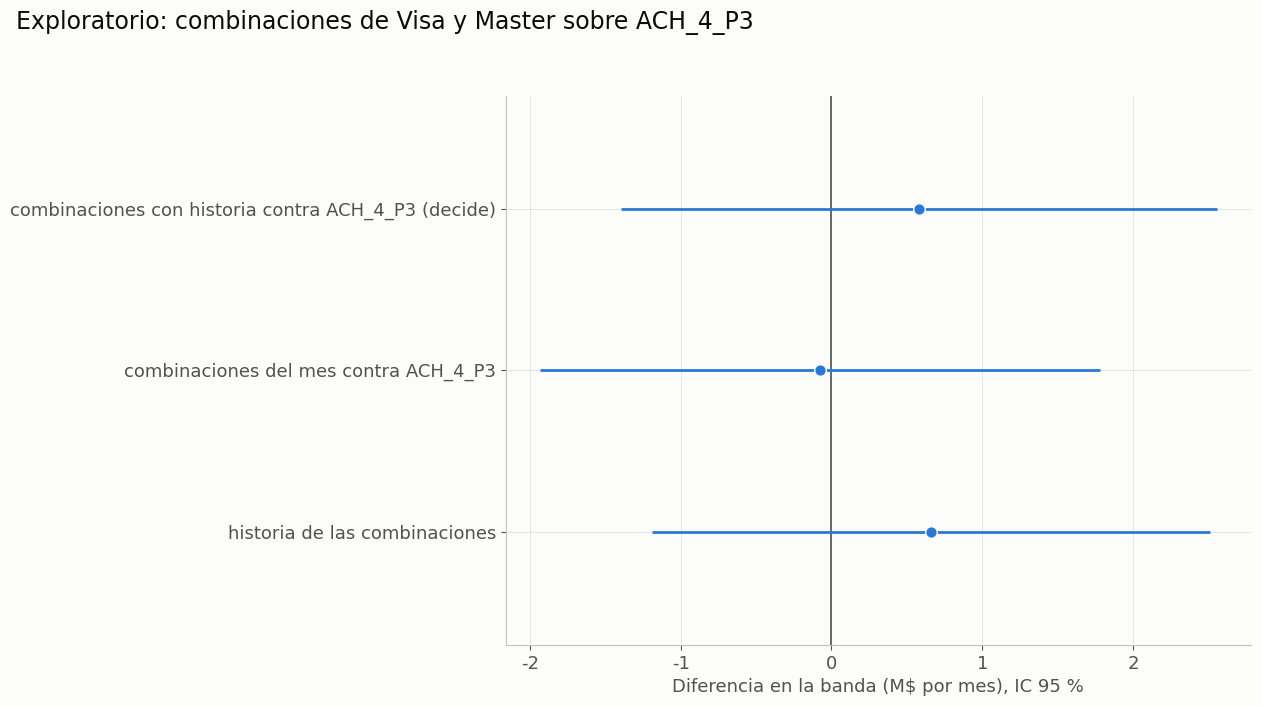

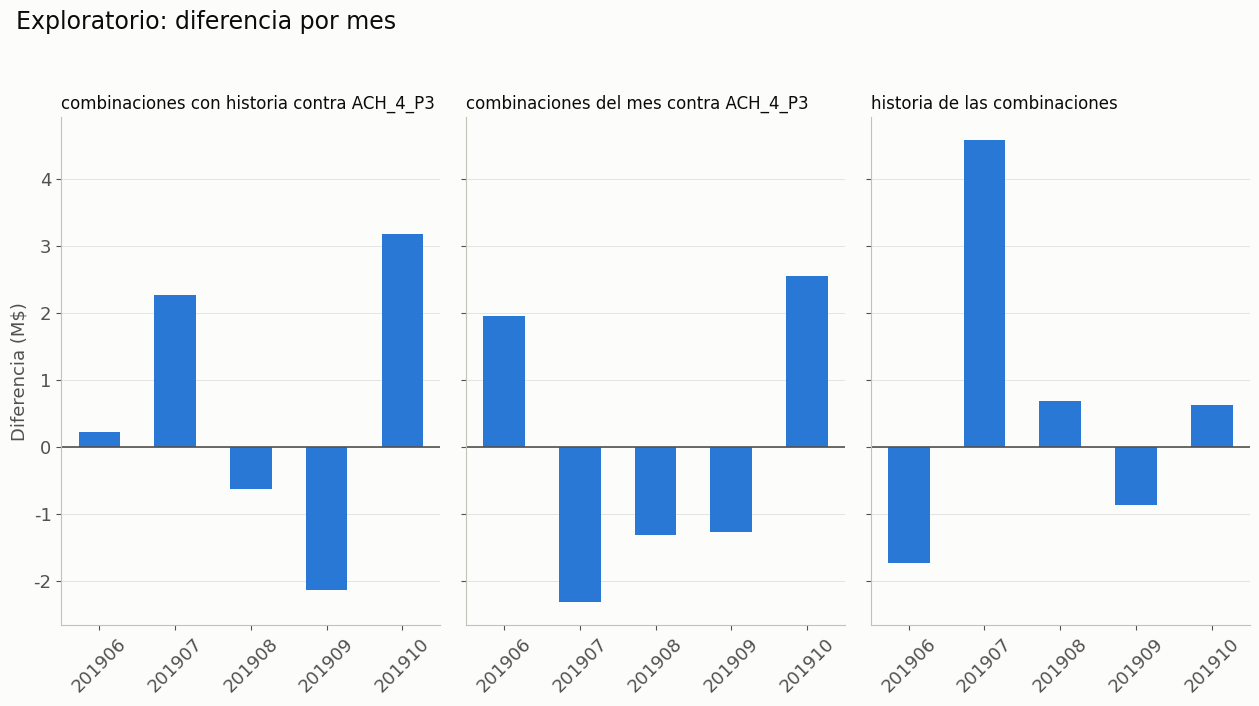

In [8]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


NOMBRES = {('ACH_4_MVH_P3', REFERENCIA): 'combinaciones con historia contra ACH_4_P3 (decide)',
           ('ACH_4_MV_P3', REFERENCIA): 'combinaciones del mes contra ACH_4_P3',
           ('ACH_4_MVH_P3', 'ACH_4_MV_P3'): 'historia de las combinaciones'}
t = comparacion.set_index(['config', 'contra'])
orden = list(CONTRASTES)
y = np.arange(len(orden))[::-1]
formato = FuncFormatter(lambda v, _: coma(v, 0 if float(v).is_integer() else 1))

fig, ax = plt.subplots(figsize=TAMANO)
ax.axvline(0, color=TINTA_2, lw=1.2)
ax.hlines(y, t.loc[orden, 'ic95_inf_M'], t.loc[orden, 'ic95_sup_M'], color=AZUL, lw=2)
ax.scatter(t.loc[orden, 'd_M'], y, s=70, color=AZUL, zorder=3, edgecolor='#fcfcfb')
ax.set_yticks(y, [NOMBRES[k] for k in orden])
ax.set_ylim(-0.7, len(orden) - 0.3)
ax.xaxis.set_major_formatter(formato)
ax.set_xlabel('Diferencia en la banda (M$ por mes), IC 95 %')
fig.suptitle('Exploratorio: combinaciones de Visa y Master sobre ACH_4_P3', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '17_1_visa_master.png', dpi=DPI)
plt.show()

fig, ejes = plt.subplots(1, len(orden), figsize=TAMANO, sharey=True)
for ax, k in zip(ejes, orden):
    ax.axhline(0, color=TINTA_2, lw=1.2)
    ax.bar([str(m) for m in MESES_EVALUADOS], [t.loc[k, f'd_{m}'] for m in MESES_EVALUADOS], color=AZUL, width=0.55)
    ax.yaxis.set_major_formatter(formato)
    ax.set_title(NOMBRES[k].replace(' (decide)', ''), loc='left', fontsize=12, wrap=True)
    ax.tick_params(axis='x', labelrotation=45)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(True)
ejes[0].set_ylabel('Diferencia (M$)')
fig.suptitle('Exploratorio: diferencia por mes', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '17_2_por_mes.png', dpi=DPI)
plt.show()

## 9. Lectura fijada antes de correr

Decide solo `ACH_4_MVH_P3` contra `ACH_4_P3`, con `d` = la diferencia media en la banda:

| `d` | Lectura |
|---|---|
| +1 M o más | Suma: `ACH_4_MVH_P3` pasa a ser la vigente |
| Entre −1 y +1 M | Empate: queda `ACH_4_P3`, que es más simple |
| −1 M o menos | Resta: queda `ACH_4_P3` |

Las otras dos comparaciones explican de dónde viene la diferencia, pero no deciden: elegir la mejor de dos después de verlas sería ajustar al ruido. El intervalo se informa siempre.

**Control 8:** las salidas anteriores no cambiaron.

In [9]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 8
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
if segundos:
    print('Segundos por modelo:', {c: round(float(np.mean(v)), 1) for c, v in segundos.items()})
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()

lectura = lambda d: 'Suma' if d >= UMBRAL else ('Resta' if d <= -UMBRAL else 'Empate')
for r in comparacion.itertuples():
    marca = ' · DECIDE' if (r.config, r.contra) == (DECIDE, REFERENCIA) else ''
    print(f'{r.config} contra {r.contra}: {r.d_M:+.2f} M ({r.ic95_inf_M:.2f} a {r.ic95_sup_M:.2f}) · error {r.error_total_M:.2f} M · '
          f'ensamble {r.d_ensamble_M:+.2f} M · semillas a favor {r.semillas_a_favor} de {N_SEMILLAS} · {lectura(r.d_M)}{marca}')

t = comparacion.set_index(['config', 'contra'])
pd.DataFrame([{'config': c, 'hipotesis': HIPOTESIS[c], 'contra': REFERENCIA, 'columnas': len(COLUMNAS_DE[c]),
               'd_M': round(t.loc[(c, REFERENCIA), 'd_M'], 3), 'resultado': lectura(t.loc[(c, REFERENCIA), 'd_M']),
               'decide': c == DECIDE} for c in CONFIGS]).to_csv(RESULTADOS / '17_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 44.2 min en total · memoria máxima 6.6 GB
Segundos por modelo: {'ACH_4_MV_P3': 45.0, 'ACH_4_MVH_P3': 54.5}

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

ACH_4_MVH_P3 contra ACH_4_P3: +0.58 M (-1.39 a 2.56) · error 1.01 M · ensamble +0.62 M · semillas a favor 5 de 5 · Empate · DECIDE
ACH_4_MV_P3 contra ACH_4_P3: -0.08 M (-1.94 a 1.78) · error 0.95 M · ensamble -0.52 M · semillas a favor 3 de 5 · Empate
ACH_4_MVH_P3 contra ACH_4_MV_P3: +0.66 M (-1.19 a 2.51) · error 0.94 M · ensamble +1.13 M · semillas a favor 4 de 5 · Empate
